## in this notebook we are going to make something where the same model predict 2 outputs

In [1]:
#cell that have all of the imports
# Data
import numpy as np
import pandas as pd

# visualization
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

# pytorch
import torch
import torch.nn.functional as F
from torch import nn, tensor
from torch.utils.data import DataLoader, Dataset

# torchvision
from torchvision import transforms, models
from torchvision.transforms import functional as TF

# fastai
from fastai.vision.all import *
from fastai.tabular.all import *
from fastai.data.transforms import RandomSplitter
from fastai.callback.hook import *

# sklearn
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]
/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import os
os.getcwd()

'/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course'

In [3]:
#make the path
path = Path("../Data/plant_comp")
trn_path = path/"train_images"

In [22]:
# index_col --> indexing by the thing that we choose (by the index as i made of the name of the column) so that i can just index with the thing i choose (name of the image here) the image
df = pd.read_csv(path/'train.csv',index_col=0)

In [23]:
print(df.nunique())
print("*"*50)
df['variety'].value_counts()

label      10
variety    10
age        18
dtype: int64
**************************************************


variety
ADT45             6992
KarnatakaPonni     988
Ponni              657
AtchayaPonni       461
Zonal              399
AndraPonni         377
Onthanel           351
IR20               114
RR                  36
Surya               32
Name: count, dtype: int64

In [16]:
df.loc['100330.jpg', 'variety']

'ADT45'

loc() vs iloc()

    # index_col NOT set → index is numbers by default
    df = pd.read_csv('train.csv')
    df.loc[0]              # works ✓ — index is numbers

    # index_col SET → index is filenames
    df = pd.read_csv('train.csv', index_col='image_id')
    df.loc['100330.jpg']   # works ✓ — index is filenames
    df.loc[0]        # BREAKS ✗ — index is no longer numbers

In [24]:
# make a fucntion that gets us the variety
def get_variety(path): return df.loc[path.name,'variety']
# Path('train/bacterial_leaf_blight/100330.jpg').name → '100330.jpg'

In [25]:
# make the dataloaders using fastai (this is the manual verison of the ImageDataLoader)
dls = DataBlock(
    blocks=(ImageBlock,CategoryBlock,CategoryBlock), # make for each file -->(image,categorical_var(disease),categorical_var(variety))
    n_inp=1, # number input = 1
    get_items=get_image_files,
    get_y=[parent_label,get_variety],# get_label is from fast_ai
    splitter=RandomSplitter(0.2),
    item_tfms=Resize(192,method='squish'),
    batch_tfms=aug_transforms(size=128,min_scale=0.75),
).dataloaders(trn_path)

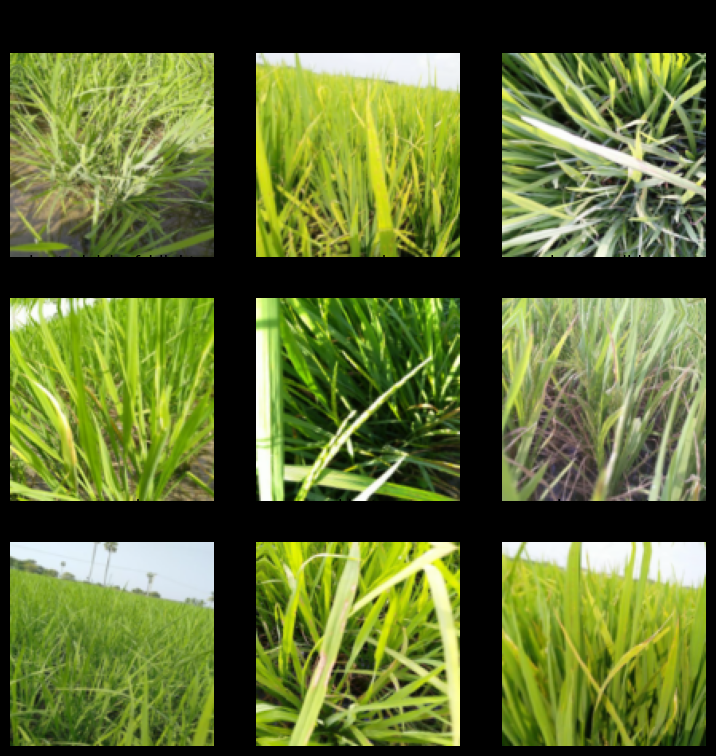

In [26]:
# lets take a look
dls.show_batch(max_n=9)

it has 2 labels

# making the models

## making a one label model(previous)

In [27]:
def disease_err(inp,disease,variety): return error_rate(inp,disease)
def disease_loss(inp,disease,variety): return F.cross_entropy(inp,disease)

In [28]:
arch = 'convnext_small_in22k'
learn = vision_learner(dls, arch, loss_func=disease_loss, metrics=disease_err, n_out=10).to_fp16()
lr = 0.01

/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/.venv/lib/python3.12/site-packages/timm/models/_factory.py:138: UserWarning: Mapping deprecated model name convnext_small_in22k to current convnext_small.fb_in22k.
  model = create_fn(


In [29]:
learn.fine_tune(5, lr)

epoch,train_loss,valid_loss,disease_err,time
0,1.293141,0.780753,0.240269,00:24


epoch,train_loss,valid_loss,disease_err,time
0,0.616354,0.431061,0.137914,00:28
1,0.469167,0.342403,0.102835,00:29
2,0.302015,0.234612,0.071600,00:29
3,0.169306,0.210238,0.057665,00:29
4,0.119784,0.188215,0.052379,00:28


## make a multi-target model

becasue this is multi-target model --> we are making our own loss

we are making the input all of the arguments even if we are not using one because this is the way fast ai handles the loss functions

In [62]:
def loss_disease(inp,disease,variety):
    return F.cross_entropy(inp[:,:10],disease)# we are making this indexing-->(images(dataloader_dim),first 10 numbers(disease_preds))

In [63]:
def loss_variety(inp,disease,variety):
    return F.cross_entropy(inp[:,10:],variety)# we are making this indexing-->(images(dataloader_dim),last 10 numbers(variety_preds))

In [64]:
def combined_loss(inp,disease,variety):
    return loss_disease(inp, disease, variety) + loss_variety(inp, disease, variety)


In [65]:
# make also the error rates
def disease_err(inp,disease,variety): return error_rate(inp[:,:10],disease)
def variety_err(inp,disease,variety): return error_rate(inp[:,10:],variety)
def disease_acc(inp,disease,variety): return 1-error_rate(inp[:,:10],disease)
def variety_acc(inp,disease,variety): return 1-error_rate(inp[:,10:],variety)

In [66]:
error_metrics = (disease_err,variety_err,disease_acc,variety_acc)

In [67]:
# all meterics
all_metrics = error_metrics + (loss_disease,loss_variety)

In [68]:
# make the learner
#we are making the out_features=20 --> 10 for the disease and 10 for the variety
learn = vision_learner(dls, arch, loss_func=combined_loss, metrics=all_metrics,n_out=20).to_fp16()

In [69]:
learn.fine_tune(5,lr)

epoch,train_loss,valid_loss,disease_err,variety_err,disease_acc,variety_acc,loss_disease,loss_variety,time
0,4.882998,3.088040,0.644402,0.310428,0.355598,0.689572,1.894979,1.193061,00:24


epoch,train_loss,valid_loss,disease_err,variety_err,disease_acc,variety_acc,loss_disease,loss_variety,time
0,3.726353,2.852031,0.602114,0.294089,0.397886,0.705911,1.765872,1.086159,00:30
1,3.229170,2.540850,0.521384,0.281115,0.478616,0.718885,1.569693,0.971157,00:30
2,2.961918,2.401656,0.488227,0.273426,0.511773,0.726574,1.492994,0.908662,00:28
3,2.809047,2.348557,0.475252,0.267179,0.524748,0.732821,1.462273,0.886284,00:28
4,2.732718,2.331445,0.471889,0.269582,0.528111,0.730418,1.449443,0.882002,00:28
